In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [4]:
df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Check the data
print(df.shape)
print(df.isnull().sum())

(200, 5)
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000
Gender
Female    112
Male       88
Name: count, dtype: int64


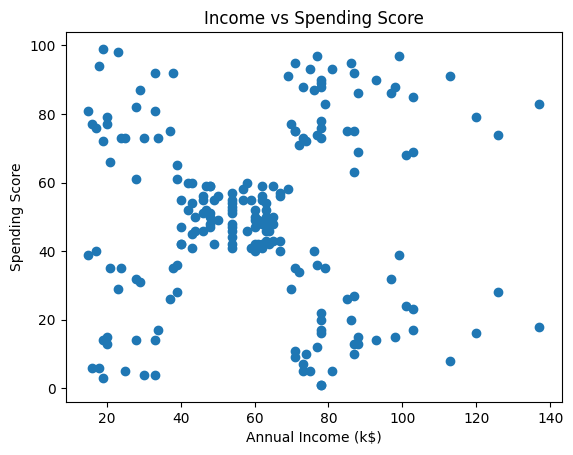

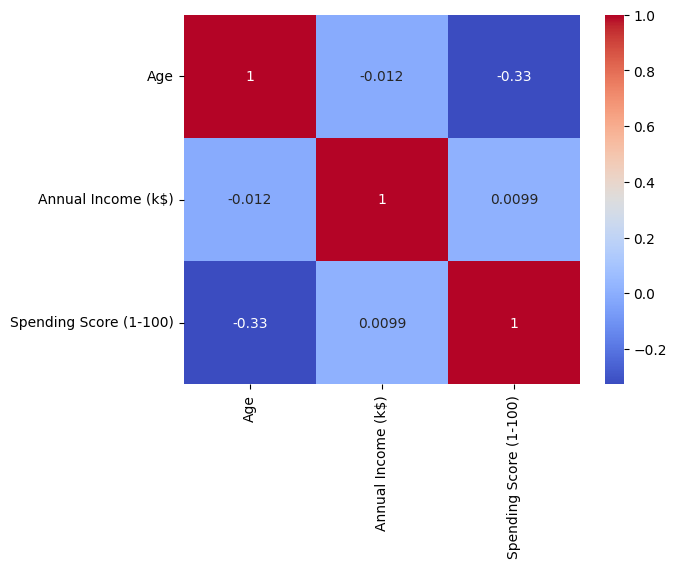

In [6]:
print(df.describe())

# Gender distribution
print(df["Gender"].value_counts())

# Visualize income and spending
plt.scatter(df["Annual Income (k$)"],
            df["Spending Score (1-100)"])

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Income vs Spending Score")
plt.show()

# Correlation analysis
sns.heatmap(df[["Age", "Annual Income (k$)",
                "Spending Score (1-100)"]].corr(),
            annot=True, cmap="coolwarm")
plt.show()

In [7]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

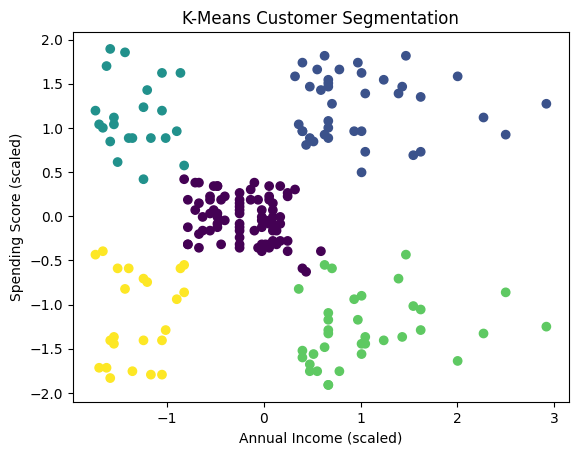

In [8]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df["KMeans_Cluster"], cmap="viridis")

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title("K-Means Customer Segmentation")
plt.show()

DBSCAN_Cluster
 0    115
 2     32
 3     27
-1     15
 1     11
Name: count, dtype: int64


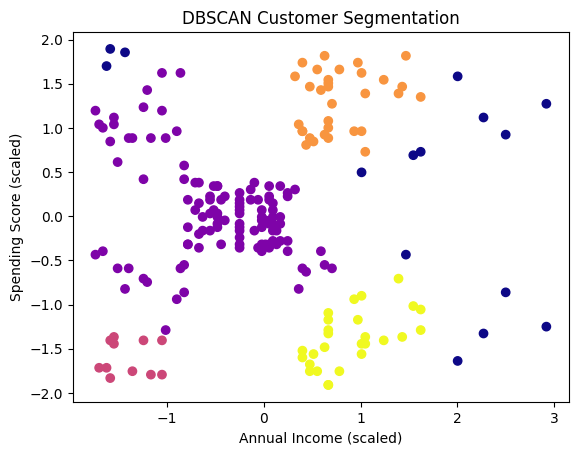

In [9]:
dbscan = DBSCAN(eps=0.4, min_samples=5)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(df["DBSCAN_Cluster"].value_counts())

plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df["DBSCAN_Cluster"], cmap="plasma")

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title("DBSCAN Customer Segmentation")
plt.show()

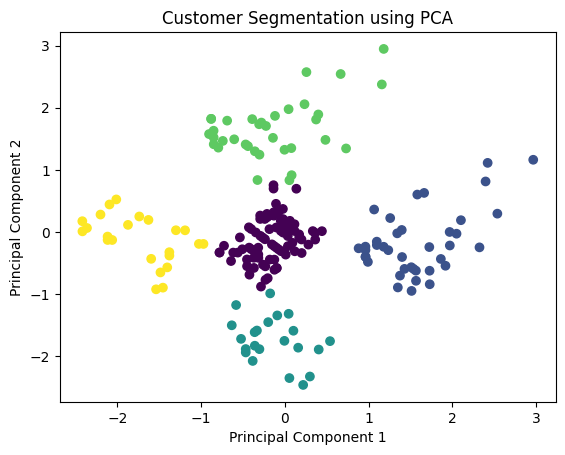

Explained variance: 1.0


In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=df["KMeans_Cluster"], cmap="viridis")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using PCA")
plt.show()

print("Explained variance:",
      pca.explained_variance_ratio_.sum())

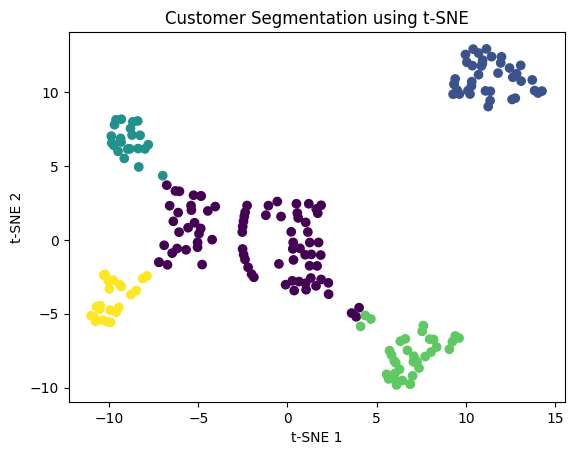

In [11]:
tsne = TSNE(n_components=2, random_state=42,
            perplexity=30, init="pca",
            learning_rate="auto")

X_tsne = tsne.fit_transform(X_scaled)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=df["KMeans_Cluster"], cmap="viridis")

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segmentation using t-SNE")
plt.show()

In [12]:
personas = df.groupby("KMeans_Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "Age": "mean",
    "CustomerID": "count"
}).round(2)

personas = personas.rename(
    columns={"CustomerID": "Number of Customers"}
)

print(personas)

                Annual Income (k$)  Spending Score (1-100)    Age  \
KMeans_Cluster                                                      
0                            55.30                   49.52  42.72   
1                            86.54                   82.13  32.69   
2                            25.73                   79.36  25.27   
3                            88.20                   17.11  41.11   
4                            26.30                   20.91  45.22   

                Number of Customers  
KMeans_Cluster                       
0                                81  
1                                39  
2                                22  
3                                35  
4                                23  


In [13]:
personas = df.groupby("KMeans_Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "Age": "mean",
    "CustomerID": "count"
}).round(2)

personas = personas.rename(
    columns={"CustomerID": "Number of Customers"}
)

print(personas)

                Annual Income (k$)  Spending Score (1-100)    Age  \
KMeans_Cluster                                                      
0                            55.30                   49.52  42.72   
1                            86.54                   82.13  32.69   
2                            25.73                   79.36  25.27   
3                            88.20                   17.11  41.11   
4                            26.30                   20.91  45.22   

                Number of Customers  
KMeans_Cluster                       
0                                81  
1                                39  
2                                22  
3                                35  
4                                23  
